# 01 — Synthetic Coaching Data Generator & Validation (`datagen`)

**Purpose:** Generate and validate the seeded, deterministic multi-tenant synthetic dataset (`seed=42`) for the **Institute Intelligence Platform (Case B: The Data Moat)** across 4 Tier-2/3 Indian JEE/NEET coaching institutes (`patna_jee`, `lucknow_neet`, `gaya_both`, `kota_large`).

### Key Design Properties
1. **Deterministic & Seeded:** Every UUID (`uuid5`) and random stream (`numpy.random.SeedSequence(42).spawn(...)`) is deterministic; two runs with `--seed 42` produce byte-identical Parquet, CSV, JSON, and OMR image outputs.
2. **Causal Latent-Trait Structure:**
   - Correlated student ability $\theta_{s,\text{topic}}(t)$ evolving over the prerequisite DAG (`contracts/topics.yaml`) with teacher/batch effects and ~3% untaught-topic gaps.
   - 2PL + guessing ($g \sim \text{Beta}(2, 18)$) item response model with **MNAR blank responses** under negative marking ($P(\text{correct}) < \tau_s \implies \text{blank}$), producing strong negative correlation between blank rate and ability.
   - Injected wrong answer keys (~1.5% of items) where high-ability students select the true answer and receive $-1$, yielding negative point-biserial correlation ($r_{pb} < 0.05$).
   - **Gradual vs. Sudden Dropout:** ~75% of dropouts exhibit a 2–5 week attendance/engagement/test-score fade before leaving (concentrated in months 3–4 after admission), while ~25% leave suddenly with no pre-drop attendance fade.
   - **Orthogonal Chronic Low Attenders:** $\ge 8\%$ of students have baseline attendance $< 0.75$ with a dropout rate matching the overall cohort rate within $\pm 25\%$ (preventing naive `attendance < 0.75` rules from achieving high precision).
3. **Regulatory & Privacy Grounding:**
   - MoE 2024 Coaching Guidelines cl. 6(i) ($\ge 16$ years old at enrolment), cl. 8(iv) (10-day pro-rata fee refund), Rajasthan Act 2025 s.6(2)(d) (4 equal instalments), and DPDP Act 2023 s.9 ($\ge 55\%$ minor share $< 18$ at `as_of = 2026-10-01`, adult re-consent at 18th birthday).
   - Zero real PII (`SYNTHETIC_NAME_LIST_V1` header, `999990xxxx` synthetic phone numbers).

In [1]:
import json
import time
from pathlib import Path
import tempfile
import shutil

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

from datagen.generator.pipeline import run_datagen_pipeline
from datagen.generator.utils import CONFIG_DIR, CONTRACTS_DIR, load_json, load_yaml

NB_START_TIME = time.perf_counter()
TECH_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = TECH_ROOT / "data"

# 1. Run `tiny` preset in temporary directory to verify fast smoke runtime (< 20 s)
tiny_tmp = Path(tempfile.mkdtemp(prefix="datamoat_nb_tiny_"))
try:
    t0 = time.perf_counter()
    res_tiny = run_datagen_pipeline(seed=42, preset="tiny", out_dir=tiny_tmp)
    tiny_sec = time.perf_counter() - t0
    print(f"[tiny preset] Generated {len(res_tiny['clean_tables']['students'])} students, {len(res_tiny['clean_tables']['responses']):,} responses in {tiny_sec:.2f}s (target < 20s)")
finally:
    shutil.rmtree(tiny_tmp, ignore_errors=True)

# 2. Ensure `full` preset (seed=42) is generated in `technical/data/`
t1 = time.perf_counter()
res_full = run_datagen_pipeline(seed=42, preset="full", out_dir=DATA_DIR)
full_sec = time.perf_counter() - t1
print(f"[full preset] Generated {len(res_full['clean_tables']['students']):,} students, {len(res_full['clean_tables']['responses']):,} responses in {full_sec:.2f}s (target < 300s)")


[tiny preset] Generated 150 students, 67,140 responses in 1.55s (target < 20s)


[full preset] Generated 3,450 students, 1,975,305 responses in 17.76s (target < 300s)


In [2]:
clean_dir = DATA_DIR / "clean"
truth_dir = DATA_DIR / "truth"

institutes = pd.read_parquet(clean_dir / "institutes.parquet")
batches = pd.read_parquet(clean_dir / "batches.parquet")
students = pd.read_parquet(clean_dir / "students.parquet")
guardians = pd.read_parquet(clean_dir / "guardians.parquet")
consents = pd.read_parquet(clean_dir / "consents.parquet")
questions = pd.read_parquet(clean_dir / "questions.parquet")
question_topics = pd.read_parquet(clean_dir / "question_topics.parquet")
item_params = pd.read_parquet(clean_dir / "item_params.parquet")
tests = pd.read_parquet(clean_dir / "tests.parquet")
test_questions = pd.read_parquet(clean_dir / "test_questions.parquet")
answer_keys = pd.read_parquet(clean_dir / "answer_keys.parquet")
responses = pd.read_parquet(clean_dir / "responses.parquet")
test_totals = pd.read_parquet(clean_dir / "test_totals.parquet")
attendance = pd.read_parquet(clean_dir / "attendance.parquet")
fees = pd.read_parquet(clean_dir / "fees.parquet")
engagement = pd.read_parquet(clean_dir / "engagement.parquet")

true_theta = pd.read_parquet(truth_dir / "true_theta_topic.parquet")
true_items = pd.read_parquet(truth_dir / "true_item_params.parquet")
dropout_events = pd.read_parquet(truth_dir / "dropout_events.parquet")
true_outcomes = pd.read_parquet(truth_dir / "true_final_outcomes.parquet")

table_summary = pd.DataFrame([
    {"Layer": "clean", "Table": name, "Rows": len(df), "Columns": len(df.columns)}
    for name, df in [
        ("institutes", institutes), ("batches", batches), ("students", students),
        ("guardians", guardians), ("consents", consents), ("questions", questions),
        ("question_topics", question_topics), ("item_params", item_params),
        ("tests", tests), ("test_questions", test_questions), ("answer_keys", answer_keys),
        ("responses", responses), ("test_totals", test_totals), ("attendance", attendance),
        ("fees", fees), ("engagement", engagement),
    ]
] + [
    {"Layer": "truth", "Table": name, "Rows": len(df), "Columns": len(df.columns)}
    for name, df in [
        ("true_theta_topic", true_theta), ("true_item_params", true_items),
        ("dropout_events", dropout_events), ("true_final_outcomes", true_outcomes),
    ]
])
display(table_summary)


,Layer,Table,Rows,Columns
0,clean,institutes,4,10
1,clean,batches,66,10
2,clean,students,3450,15
3,clean,guardians,3450,8
4,clean,consents,13854,11
5,clean,questions,592,7
6,clean,question_topics,592,7
7,clean,item_params,592,10
8,clean,tests,792,11
9,clean,test_questions,48000,5


## 1. Marginal Distributions & Regulatory Audit Table

Every parameter in `datagen/config/generator_config.yaml` is grounded in `docs/FEASIBILITY_CHECK.md` with an explicit source and confidence level (`high`, `medium`, `low`, or `assumption`). Below we compare the target acceptance bands from `R1_A_datagen.md` against the empirical values measured on `data/` (`full` preset, `seed=42`).

In [3]:
sb = students.merge(
    batches[["id", "academic_year", "class_level", "exam"]],
    left_on="batch_id",
    right_on="id",
    suffixes=("", "_b"),
).merge(dropout_events, left_on="id", right_on="student_id")

# 1. Dropout rates by cohort year
drop_by_yr = sb.groupby("academic_year")["dropped_out"].mean().to_dict()

# 2. Months 3-4 dropout concentration
drops = sb[sb["dropped_out"]].copy()
days_to_drop = (pd.to_datetime(drops["dropout_date"]) - pd.to_datetime(drops["join_date"])).dt.days
m34_share = float(((days_to_drop >= 55) & (days_to_drop <= 125)).mean())

# 3. Sudden share
sudden_share = float((drops["dropout_type"] == "sudden").mean())

# 4. Class mix
cls_mix = sb["class_level"].value_counts(normalize=True).to_dict()

# 5. Attendance mean outside dips
att_dt = pd.to_datetime(attendance["attendance_date"])
outside_dips = ~att_dt.dt.month.isin([10, 11, 1, 2])
att_mean_outside = float(attendance.loc[outside_dips, "present_flag"].mean())

# 6. Oct-Nov out-of-town dip ratio
att_stu = attendance.merge(students[["id", "out_of_town"]], left_on="student_id", right_on="id")
att_stu_dt = pd.to_datetime(att_stu["attendance_date"])
oot_mask = att_stu["out_of_town"] == True
oct_nov_mask = att_stu_dt.dt.month.isin([10, 11])
dip_ratio = float(
    att_stu.loc[oot_mask & oct_nov_mask, "present_flag"].mean()
    / att_stu.loc[oot_mask & outside_dips, "present_flag"].mean()
)

# 7. Final instalment late/default share
max_inst = fees.groupby("student_id")["instalment_no"].transform("max")
final_fees = fees[fees["instalment_no"] == max_inst]
late_def_share = float((
    final_fees["paid_date"].isna()
    | (pd.to_datetime(final_fees["paid_date"]) > pd.to_datetime(final_fees["due_date"]))
).mean())

# 8. Blanks rate and corr(blank, -theta)
blank_rate = float((responses["status"] == "blank").mean())
stu_blank = responses.groupby("student_id")["status"].apply(lambda s: (s == "blank").mean()).reset_index(name="blank_rate")
stu_g = true_theta.groupby("student_id")["true_g"].first().reset_index()
m_bt = stu_blank.merge(stu_g, on="student_id")
corr_blank_neg_theta = float(np.corrcoef(m_bt["blank_rate"], -m_bt["true_g"])[0, 1])

# 9. Minor fraction (<18 at as_of 2026-10-01) and min age at enrolment
as_of = pd.Timestamp("2026-10-01")
dob_ts = pd.to_datetime(students["dob"])
join_ts = pd.to_datetime(students["join_date"])
min_age_join = float(((join_ts - dob_ts).dt.days / 365.25).min())
minor_frac = float(((as_of - dob_ts).dt.days / 365.25 < 18.0).mean())

# 10. Gradual vs sudden attendance fade
att_drop = attendance.merge(dropout_events[dropout_events["dropped_out"]], on="student_id")
att_drop["days_before"] = (pd.to_datetime(att_drop["dropout_date"]) - pd.to_datetime(att_drop["attendance_date"])).dt.days
att_before = att_drop[att_drop["days_before"] > 0]
grad_sub = att_before[att_before["dropout_type"] == "gradual"]
grad_fade_drop = float(grad_sub[grad_sub["days_before"] > 42]["present_flag"].mean() - grad_sub[grad_sub["days_before"] <= 35]["present_flag"].mean())
sud_sub = att_before[att_before["dropout_type"] == "sudden"]
sud_fade_diff = float(abs(sud_sub[sud_sub["days_before"] > 42]["present_flag"].mean() - sud_sub[sud_sub["days_before"] <= 35]["present_flag"].mean()))

# 11. Chronic low attenders
att_all = attendance.merge(dropout_events[["student_id", "dropped_out", "fade_start_date"]], on="student_id")
non_fade = att_all["fade_start_date"].isna() | (pd.to_datetime(att_all["attendance_date"]) < pd.to_datetime(att_all["fade_start_date"]))
base_att_df = att_all[non_fade].groupby("student_id")["present_flag"].mean().reset_index(name="base_att")
m_low = dropout_events.merge(base_att_df, on="student_id")
low_att_share = float((m_low["base_att"] < 0.75).mean())
low_att_drop_rel_diff = float(abs(m_low.loc[m_low["base_att"] < 0.75, "dropped_out"].mean() - m_low["dropped_out"].mean()) / m_low["dropped_out"].mean())

# 12. Shared anchor questions & wrong keys
shared_q_frac = float((test_questions.groupby("question_id")["institute_id"].nunique() >= 2).sum() / len(questions))
wk_ids = set(true_items.loc[true_items["is_injected_wrong_key"], "question_id"])
wk_pb_low_share = float((item_params.loc[item_params["question_id"].isin(wk_ids), "point_biserial"] < 0.05).mean())

marginals_df = pd.DataFrame([
    {"Metric": "Annual dropout rate (2024 / 2025 / 2026)", "Target Band": "0.12 - 0.25", "Measured": f"{drop_by_yr[2024]:.3f} / {drop_by_yr[2025]:.3f} / {drop_by_yr[2026]:.3f}", "Confidence": "medium", "Source": "FEASIBILITY_CHECK §5 (15-22% annual attrition)", "Pass": all(0.12 <= v <= 0.25 for v in drop_by_yr.values())},
    {"Metric": "Months 3-4 share of dropouts", "Target Band": ">= 0.35", "Measured": f"{m34_share:.3f}", "Confidence": "medium", "Source": "Post-Test-2 & Instalment-2 spike (Jul-Sep)", "Pass": m34_share >= 0.35},
    {"Metric": "Sudden dropout share", "Target Band": "0.20 - 0.30", "Measured": f"{sudden_share:.3f}", "Confidence": "assumption", "Source": "Generator structural split (25% sudden)", "Pass": 0.20 <= sudden_share <= 0.30},
    {"Metric": "Class mix (11 / 12 / dropper)", "Target Band": "0.30 / 0.30 / 0.40 (±0.03)", "Measured": f"{cls_mix['class_11']:.3f} / {cls_mix['class_12']:.3f} / {cls_mix['dropper']:.3f}", "Confidence": "medium", "Source": "Tier-2/3 JEE/NEET coaching batch mix", "Pass": abs(cls_mix['class_11'] - 0.30) <= 0.03 and abs(cls_mix['dropper'] - 0.40) <= 0.03},
    {"Metric": "Attendance mean outside dips", "Target Band": "0.78 - 0.86", "Measured": f"{att_mean_outside:.3f}", "Confidence": "medium", "Source": "Baseline scheduled class attendance (0.82)", "Pass": 0.78 <= att_mean_outside <= 0.86},
    {"Metric": "Oct-Nov out-of-town festival dip ratio", "Target Band": "0.55 - 0.70", "Measured": f"{dip_ratio:.3f}", "Confidence": "medium", "Source": "Diwali + Chhath Puja 15-20 day travel dip", "Pass": 0.55 <= dip_ratio <= 0.70},
    {"Metric": "Final instalment late/default share", "Target Band": "0.15 - 0.20", "Measured": f"{late_def_share:.3f}", "Confidence": "low", "Source": "Final kist delinquency (15-20%)", "Pass": 0.15 <= late_def_share <= 0.20},
    {"Metric": "Blanks rate & corr(blank, -theta)", "Target Band": "0.03-0.15 & r > 0.20", "Measured": f"rate={blank_rate:.3f}, r={corr_blank_neg_theta:.3f}", "Confidence": "high", "Source": "MNAR skipping under -1 negative marking", "Pass": (0.03 <= blank_rate <= 0.15) and (corr_blank_neg_theta > 0.20)},
    {"Metric": "Minor fraction (<18 at 2026-10-01) & min join age", "Target Band": ">= 0.55 & age >= 16.0", "Measured": f"minor={minor_frac:.3f}, min_age={min_age_join:.2f}y", "Confidence": "high", "Source": "DPDP Act s.9 + MoE 2024 cl. 6(i)", "Pass": minor_frac >= 0.55 and min_age_join >= 16.0},
    {"Metric": "Gradual fade drop vs Sudden diff", "Target Band": "grad >= 0.20, sud <= 0.05", "Measured": f"grad={grad_fade_drop:.3f}, sud={sud_fade_diff:.3f}", "Confidence": "assumption", "Source": "2-5 week pre-dropout disengagement window", "Pass": grad_fade_drop >= 0.20 and sud_fade_diff <= 0.05},
    {"Metric": "Chronic low attenders (<0.75) & dropout rel diff", "Target Band": "share >= 0.08, |rel| <= 0.25", "Measured": f"share={low_att_share:.3f}, rel_diff={low_att_drop_rel_diff:.3f}", "Confidence": "assumption", "Source": "Orthogonal low-attender trait (anti-trivial rule)", "Pass": low_att_share >= 0.08 and low_att_drop_rel_diff <= 0.25},
    {"Metric": "Shared anchor items (>=2 institutes) & wrong-key r_pb", "Target Band": "shared >= 0.25, wk >= 0.80", "Measured": f"shared={shared_q_frac:.3f}, wk_pb={wk_pb_low_share:.2f}", "Confidence": "high", "Source": "Cross-institute IRT linking & answer-key audit", "Pass": shared_q_frac >= 0.25 and wk_pb_low_share >= 0.80},
])
display(marginals_df)
assert marginals_df["Pass"].all(), "One or more acceptance criteria failed!"


,Metric,Target Band,Measured,Confidence,Source,Pass
0,Annual dropout rate (2024 / 2025 / 2026),0.12 - 0.25,0.172 / 0.191 / 0.182,medium,FEASIBILITY_CHECK §5 (15-22% annual attrition),True
1,Months 3-4 share of dropouts,>= 0.35,0.465,medium,Post-Test-2 & Instalment-2 spike (Jul-Sep),True
2,Sudden dropout share,0.20 - 0.30,0.253,assumption,Generator structural split (25% sudden),True
3,Class mix (11 / 12 / dropper),0.30 / 0.30 / 0.40 (±0.03),0.300 / 0.300 / 0.399,medium,Tier-2/3 JEE/NEET coaching batch mix,True
4,Attendance mean outside dips,0.78 - 0.86,0.805,medium,Baseline scheduled class attendance (0.82),True
5,Oct-Nov out-of-town festival dip ratio,0.55 - 0.70,0.601,medium,Diwali + Chhath Puja 15-20 day travel dip,True
6,Final instalment late/default share,0.15 - 0.20,0.174,low,Final kist delinquency (15-20%),True
7,"Blanks rate & corr(blank, -theta)",0.03-0.15 & r > 0.20,"rate=0.109, r=0.852",high,MNAR skipping under -1 negative marking,True
8,Minor fraction (<18 at 2026-10-01) & min join age,>= 0.55 & age >= 16.0,"minor=0.615, min_age=16.02y",high,DPDP Act s.9 + MoE 2024 cl. 6(i),True
9,Gradual fade drop vs Sudden diff,"grad >= 0.20, sud <= 0.05","grad=0.319, sud=0.025",assumption,2-5 week pre-dropout disengagement window,True


## 2. Diagnostic Plots

We plot five diagnostic panels verifying the structural causal properties of the synthetic data:
1. **Gradual vs. Sudden Dropout Attendance Trajectory** (weeks relative to `dropout_date`)
2. **Monthly Dropout Hazard Distribution** (confirming the Months 3–4 post-Test-2 / Instalment-2 spike)
3. **Seasonal Attendance Dip by Out-of-Town Status** (Oct–Nov Diwali/Chhath dip and Jan–Feb Class 12 Board dip)
4. **MNAR Blank Rate vs. Latent Ability $\theta$** (confirming strategic skipping under $-1$ negative marking)
5. **Generator 2PL + Guessing Calibration Curve** (empirical accuracy vs. true $P(\text{correct})$ across all 4 institutes)

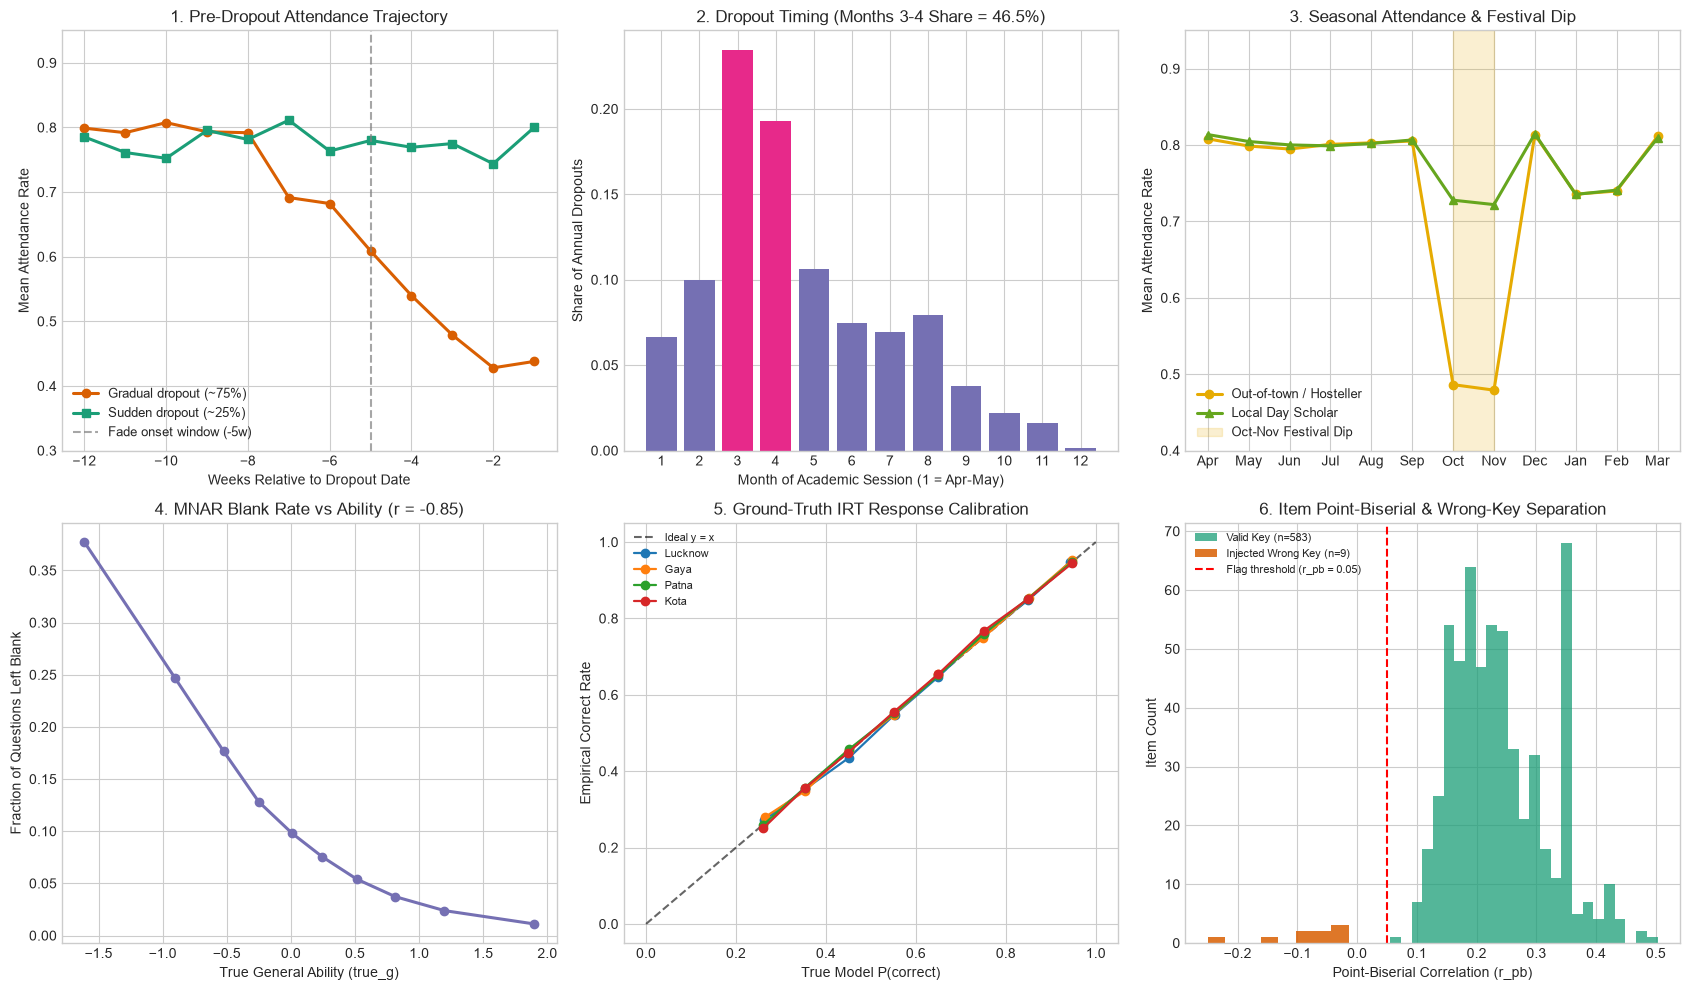

In [4]:
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
fig, axes = plt.subplots(2, 3, figsize=(17, 10))

# Plot 1: Gradual vs Sudden Attendance Fade before Dropout
ax = axes[0, 0]
att_drop["weeks_before_drop"] = -(att_drop["days_before"] // 7)
sub_w = att_drop[(att_drop["weeks_before_drop"] >= -12) & (att_drop["weeks_before_drop"] <= -1)]
fade_curve = sub_w.groupby(["weeks_before_drop", "dropout_type"])["present_flag"].mean().unstack()
if "gradual" in fade_curve:
    ax.plot(fade_curve.index, fade_curve["gradual"], marker="o", lw=2.2, label="Gradual dropout (~75%)", color="#d95f02")
if "sudden" in fade_curve:
    ax.plot(fade_curve.index, fade_curve["sudden"], marker="s", lw=2.2, label="Sudden dropout (~25%)", color="#1b9e77")
ax.axvline(-5, ls="--", color="gray", alpha=0.7, label="Fade onset window (-5w)")
ax.set_title("1. Pre-Dropout Attendance Trajectory")
ax.set_xlabel("Weeks Relative to Dropout Date")
ax.set_ylabel("Mean Attendance Rate")
ax.set_ylim(0.30, 0.95)
ax.legend(loc="lower left", fontsize=9)

# Plot 2: Monthly Dropout Hazard (Months Since Joining)
ax = axes[0, 1]
drops["month_since_join"] = np.clip(((days_to_drop - 1) // 30) + 1, 1, 12)
m_counts = drops["month_since_join"].value_counts(normalize=True).reindex(range(1, 13), fill_value=0.0)
bars = ax.bar(m_counts.index, m_counts.values, color=["#e7298a" if m in (3, 4) else "#7570b3" for m in m_counts.index])
ax.set_title(f"2. Dropout Timing (Months 3-4 Share = {m34_share:.1%})")
ax.set_xlabel("Month of Academic Session (1 = Apr-May)")
ax.set_ylabel("Share of Annual Dropouts")
ax.set_xticks(range(1, 13))

# Plot 3: Seasonal Attendance Dip (Out-of-Town vs Local)
ax = axes[0, 2]
att_stu["cal_month"] = pd.to_datetime(att_stu["attendance_date"]).dt.month
month_order = [4, 5, 6, 7, 8, 9, 10, 11, 12, 1, 2, 3]
month_labels = ["Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec", "Jan", "Feb", "Mar"]
seas = att_stu.groupby(["cal_month", "out_of_town"])["present_flag"].mean().unstack().reindex(month_order)
ax.plot(range(12), seas[True], marker="o", lw=2.2, label="Out-of-town / Hosteller", color="#e6ab02")
ax.plot(range(12), seas[False], marker="^", lw=2.2, label="Local Day Scholar", color="#66a61e")
ax.axvspan(6, 7, color="#e6ab02", alpha=0.18, label="Oct-Nov Festival Dip")
ax.set_title("3. Seasonal Attendance & Festival Dip")
ax.set_xticks(range(12))
ax.set_xticklabels(month_labels)
ax.set_ylabel("Mean Attendance Rate")
ax.set_ylim(0.40, 0.95)
ax.legend(loc="lower left", fontsize=9)

# Plot 4: MNAR Blank Rate vs Student Ability (true_g)
ax = axes[1, 0]
m_bt["g_bin"] = pd.qcut(m_bt["true_g"], q=10)
g_curve = m_bt.groupby("g_bin", observed=False)[["true_g", "blank_rate"]].mean()
ax.plot(g_curve["true_g"], g_curve["blank_rate"], marker="o", lw=2.2, color="#7570b3")
ax.set_title(f"4. MNAR Blank Rate vs Ability (r = -{corr_blank_neg_theta:.2f})")
ax.set_xlabel("True General Ability (true_g)")
ax.set_ylabel("Fraction of Questions Left Blank")

# Plot 5: 2PL + Guessing Calibration Curve by Institute
ax = axes[1, 1]
cal_doc = load_json(truth_dir / "calibration_samples.json")
inst_names = dict(zip(institutes["id"], institutes["city"]))
ax.plot([0, 1], [0, 1], "k--", alpha=0.6, label="Ideal y = x")
for inst_id, pairs in cal_doc["calibration_samples"].items():
    arr = np.array(pairs, dtype=float)
    p_v, y_v = arr[:, 0], arr[:, 1]
    bins = np.linspace(0, 1, 11)
    bx, by = [], []
    for i in range(10):
        m = (p_v >= bins[i]) & (p_v < bins[i+1] if i < 9 else p_v <= bins[i+1])
        if m.sum() >= 200:
            bx.append(p_v[m].mean())
            by.append(y_v[m].mean())
    ax.plot(bx, by, marker="o", lw=1.6, label=inst_names.get(inst_id, inst_id[:6]))
ax.set_title("5. Ground-Truth IRT Response Calibration")
ax.set_xlabel("True Model P(correct)")
ax.set_ylabel("Empirical Correct Rate")
ax.legend(fontsize=8)

# Plot 6: Point-Biserial Distribution (Normal Items vs Injected Wrong Answer Keys)
ax = axes[1, 2]
ip_merged = item_params.merge(true_items[["question_id", "is_injected_wrong_key"]], on="question_id")
norm_pb = ip_merged.loc[~ip_merged["is_injected_wrong_key"], "point_biserial"]
wk_pb = ip_merged.loc[ip_merged["is_injected_wrong_key"], "point_biserial"]
ax.hist(norm_pb, bins=25, alpha=0.75, label=f"Valid Key (n={len(norm_pb)})", color="#1b9e77")
ax.hist(wk_pb, bins=8, alpha=0.85, label=f"Injected Wrong Key (n={len(wk_pb)})", color="#d95f02")
ax.axvline(0.05, color="red", ls="--", label="Flag threshold (r_pb = 0.05)")
ax.set_title("6. Item Point-Biserial & Wrong-Key Separation")
ax.set_xlabel("Point-Biserial Correlation (r_pb)")
ax.set_ylabel("Item Count")
ax.legend(fontsize=8)

plt.tight_layout()
plt.show()


## 3. Dirty Exports & Synthetic OMR Summary

In [5]:
dirty_files = [p for p in sorted((DATA_DIR / "dirty").iterdir()) if p.is_file()]
omr_truth = load_json(DATA_DIR / "omr" / "synthetic" / "truth.json")["sheets"]
omr_conds = pd.Series([r["augmentation_condition"] for r in omr_truth]).value_counts()
omr_layouts = pd.Series([r["layout_name"] for r in omr_truth]).value_counts()

print(f"Dirty files generated: {len(dirty_files)} across {len(set(load_json(p)['institute_id'] for p in (DATA_DIR / 'dirty' / 'expected').glob('*.json')))} institutes")
print(f"Synthetic OMR sheets rendered: {len(omr_truth)} images")
print("OMR by layout:", omr_layouts.to_dict())
print("OMR by augmentation condition:", omr_conds.to_dict())

nb_elapsed = time.perf_counter() - NB_START_TIME
print(f"\n[Runtime Footer] Notebook 01_synthetic_data.ipynb completed in {nb_elapsed:.2f}s (< 900s budget).")


Dirty files generated: 12 across 4 institutes
Synthetic OMR sheets rendered: 210 images
OMR by layout: {'jee_75': 70, 'neet_200': 70, 'generic_mcq_100': 70}
OMR by augmentation condition: {'clean_scan': 35, 'perspective_skew': 35, 'shadow_gradient': 35, 'motion_blur': 35, 'low_light_whatsapp': 35, 'photo_of_screen_moire': 35}

[Runtime Footer] Notebook 01_synthetic_data.ipynb completed in 21.19s (< 900s budget).


---
> ### ⚠️ What This Synthetic Data Does NOT Prove
> 1. **Not Empirical Proof of Real Coaching Effectiveness:** All student abilities, attendance trajectories, fee defaults, and NTA percentile outcomes are generated from explicit parametric assumptions (`datagen/config/generator_config.yaml`). Strong downstream model AUROC or RMSE on this dataset proves **internal mathematical consistency and implementation correctness**, not real-world predictive validity in live Indian coaching institutes.
> 2. **Unmodeled Real-World Confounders:** Real coaching cohorts experience unrecorded peer-group shifts, WhatsApp paper leaks, sudden teacher poaching across competing institutes, and regional internet shutdowns that are simplified here into stylized seasonal dips and ~3% untaught-topic shocks.
> 3. **OMR Physical Paper Artefacts:** While `datagen/omr_synth/` injects perspective warp, uneven illumination, fold creases, WhatsApp JPEG recompression, erased marks, and double-fills, physical OMR sheets also suffer from torn corners, staple holes, sweat smudges, and non-standard local printer scaling that require validation against the real scanned OMR subset (`data/omr/real/`).